🏥 AI-Driven Multi-Disease Health Risk Prediction System
--------

--------



👥 Student Names & IDs
------

Osama Abutaha

Ahmad Baabod

Albaraa  Mashaab

Omar Abdulkarim

------


Project Summary
------

In this project, we build an AI-based health assessment system that analyzes real medical data for Heart Disease, Diabetes, and Sleep-related health issues. By training multiple machine-learning models on clinical datasets, the system learns patterns commonly associated with disease risk.

The goal is to allow a user to answer simple health-related questions, and the AI will provide:
- A risk prediction
- Confidence percentage
- Health recommendations

This system is intended to help early awareness, support preventive healthcare, and assist users in monitoring lifestyle-related risk factors in an easy and user-friendly way.

-------



Importing libraries



In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

importing the dataets

In [5]:
import pandas as pd

sleep_df = pd.read_csv('data/Sleep_health_and_lifestyle_dataset.csv')
display(sleep_df.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Data Cleaning

In [6]:
sleep_df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


In [7]:
sleep_df.shape

(374, 13)

In [8]:

sleep_df['Sleep Disorder'].unique()

array([nan, 'Sleep Apnea', 'Insomnia'], dtype=object)

In [9]:
sleep_df['Sleep Disorder'].fillna('None', inplace=True)

/tmp/ipython-input-1727516701.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sleep_df['Sleep Disorder'].fillna('None', inplace=True)


In [10]:
sleep_df['Sleep Disorder'].unique()

array(['None', 'Sleep Apnea', 'Insomnia'], dtype=object)

In [11]:
print(f"Number of duplicated columns: {sleep_df.duplicated().sum()}")

Number of duplicated columns: 0


In [12]:
sleep_df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


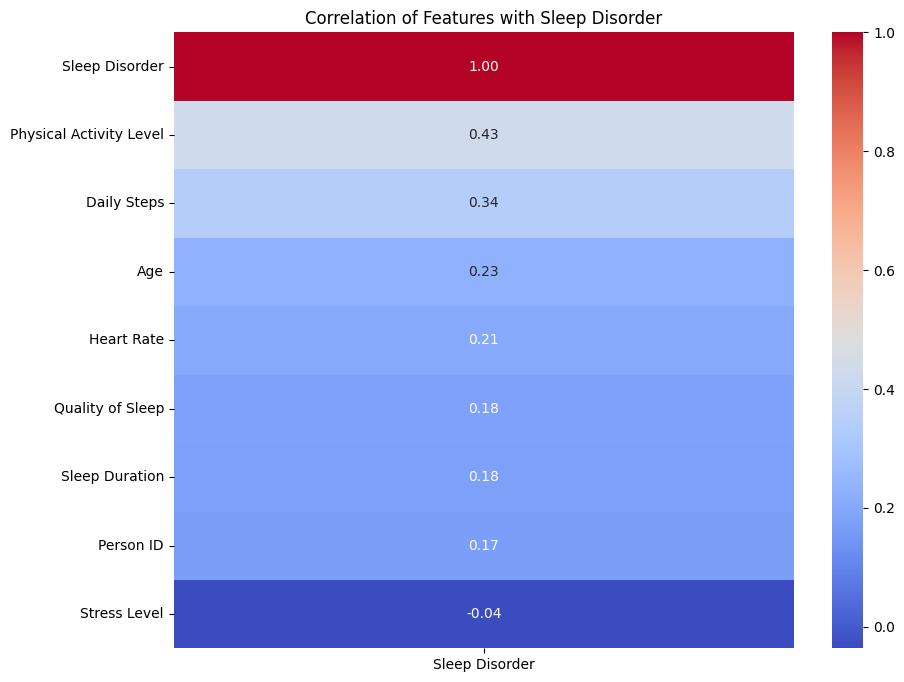

In [13]:
from sklearn.preprocessing import LabelEncoder

# Create a temporary copy to ensure 'Sleep Disorder' is numeric for correlation
temp_sleep_df = sleep_df.copy()

# Check if 'Sleep Disorder' is still an object type and encode if necessary
# This ensures the column is numeric for correlation calculation even if the global sleep_df state is inconsistent.
if temp_sleep_df['Sleep Disorder'].dtype == 'object':
    le = LabelEncoder()
    temp_sleep_df['Sleep Disorder'] = le.fit_transform(temp_sleep_df['Sleep Disorder'])

correlation_matrix = temp_sleep_df.corr(numeric_only=True)
sleep_disorder_corr = correlation_matrix['Sleep Disorder'].sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.heatmap(sleep_disorder_corr.to_frame(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation of Features with Sleep Disorder')
plt.show()

This chart, a heatmap, shows how strongly each factor is related to 'Sleep Disorder'.

Higher positive numbers (like Physical Activity Level at 0.43 and Daily Steps at 0.34) mean that as these factors increase, the likelihood of having a sleep disorder tends to increase.
Numbers closer to zero (like Stress Level at -0.036) indicate a very weak or almost no relationship.
In simple terms, more physical activity and daily steps are moderately linked to sleep disorders in this dataset. Other factors like Age, Heart Rate, Quality of Sleep, and Sleep Duration also show some positive correlation, but to a lesser extent.






Checking the unique values for each column




In [15]:
cols_to_check = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder', 'Blood Pressure']

for col in cols_to_check:
    unique_vals = sleep_df[col].dropna().unique()
    print(f"\nUnique values in '{col}':")
    for val in unique_vals:
        print(f" - {val}")


Unique values in 'Gender':
 - Male
 - Female

Unique values in 'Occupation':
 - Software Engineer
 - Doctor
 - Sales Representative
 - Teacher
 - Nurse
 - Engineer
 - Accountant
 - Scientist
 - Lawyer
 - Salesperson
 - Manager

Unique values in 'BMI Category':
 - Overweight
 - Normal
 - Obese
 - Normal Weight

Unique values in 'Sleep Disorder':
 - None
 - Sleep Apnea
 - Insomnia

Unique values in 'Blood Pressure':
 - 126/83
 - 125/80
 - 140/90
 - 120/80
 - 132/87
 - 130/86
 - 117/76
 - 118/76
 - 128/85
 - 131/86
 - 128/84
 - 115/75
 - 135/88
 - 129/84
 - 130/85
 - 115/78
 - 119/77
 - 121/79
 - 125/82
 - 135/90
 - 122/80
 - 142/92
 - 140/95
 - 139/91
 - 118/75


In [16]:
sleep_df['BMI Category'] = sleep_df['BMI Category'].replace('Normal Weight', 'Normal')
print(sleep_df['BMI Category'].unique())

['Overweight' 'Normal' 'Obese']


In [17]:
sleep_df[['Systolic_BP', 'Diastolic_BP']] = sleep_df['Blood Pressure'].str.split('/', expand=True).astype(float)
sleep_df.drop('Blood Pressure', axis=1, inplace=True)


In [18]:
sleep_df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126.0,83.0
1,2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125.0,80.0
2,3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125.0,80.0
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140.0,90.0
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140.0,90.0




**model_training**

Preparing the Data to train the model

In [19]:
label_cols = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']
sleep_label_encoders = {}

for col in label_cols:
    le = LabelEncoder()
    sleep_df[col] = le.fit_transform(sleep_df[col])
    sleep_label_encoders[col] = le  # Save encoders if you want to inverse later


sleep_df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,1,27,9,6.1,6,42,6,2,77,4200,1,126.0,83.0
1,2,1,28,1,6.2,6,60,8,0,75,10000,1,125.0,80.0
2,3,1,28,1,6.2,6,60,8,0,75,10000,1,125.0,80.0
3,4,1,28,6,5.9,4,30,8,1,85,3000,2,140.0,90.0
4,5,1,28,6,5.9,4,30,8,1,85,3000,2,140.0,90.0


In [20]:
encoded = sleep_df['Sleep Disorder'].unique()
print(sleep_label_encoders['Sleep Disorder'].inverse_transform(encoded))

['None' 'Sleep Apnea' 'Insomnia']


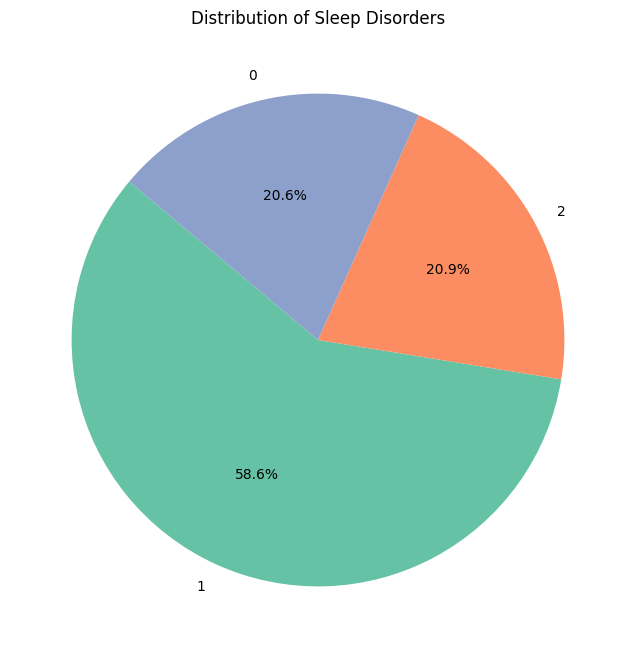

--------------------------------------


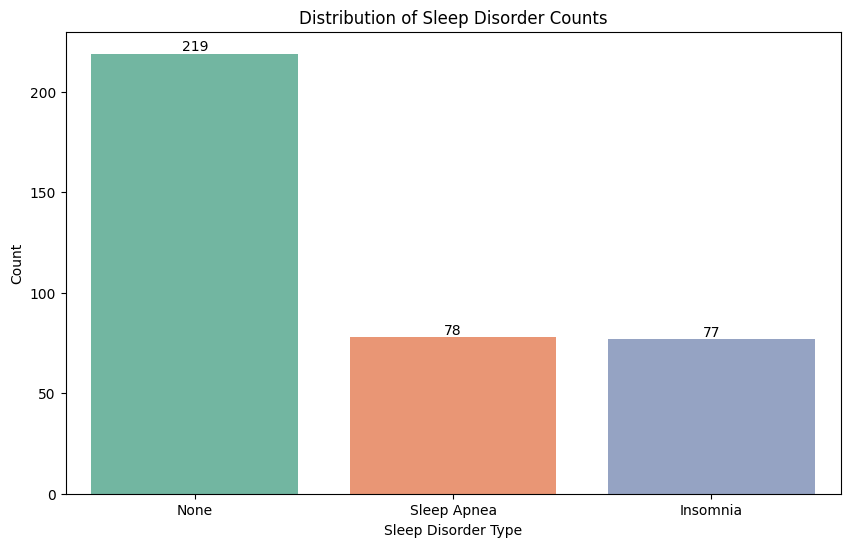

In [66]:
sleep_disorder_counts = sleep_df['Sleep Disorder'].value_counts()

# Get the actual sleep disorder names for plotting
sleep_disorder_names = sleep_label_encoders['Sleep Disorder'].inverse_transform(sleep_disorder_counts.index)

plt.figure(figsize=(8, 8))
sleep_disorder_counts.plot(kind='pie', autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Set2"))
plt.title('Distribution of Sleep Disorders')
plt.ylabel('')
plt.show()

print("--------------------------------------")

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=sleep_disorder_names, y=sleep_disorder_counts.values, palette='Set2', hue=sleep_disorder_names, legend=False)
plt.title('Distribution of Sleep Disorder Counts')
plt.xlabel('Sleep Disorder Type')
plt.ylabel('Count')

# Add the counts on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.show()

This set of charts illustrates the distribution of different sleep disorders within the dataset.

The pie chart clearly shows that a large majority of individuals (58.6%) do not have any diagnosed sleep disorder ('None').
The remaining portion is almost equally divided between those with Sleep Apnea (20.9%) and Insomnia (20.6%).
The heatmap provides the exact counts for each category, confirming that 'None' is the most prevalent, followed by 'Sleep Apnea' and 'Insomnia' with very similar numbers.

In [21]:
X = sleep_df.drop(['Person ID', 'Sleep Disorder'], axis=1)
y = sleep_df['Sleep Disorder']

In [22]:
X_train_sleep, X_test_sleep, y_train_sleep, y_test_sleep = train_test_split(X, y, test_size=0.2, random_state=42)


# Scale the features using StandardScaler
scaler_sleep = StandardScaler()
X_train_sleep_scaled = scaler_sleep.fit_transform(X_train_sleep)  # Fit on training data and transform
X_test_sleep_scaled = scaler_sleep.transform(X_test_sleep)  # Transform the test data (no fitting)


In [23]:
# MODEL TRAINING FUNCTION
def fit_ml_models(algo, params, model_name,X_train_scaled,X_test_scaled,y_train,y_test):
    print(f"\n================ {model_name} ================")
    grid = GridSearchCV(estimator=algo, param_grid=params, cv=5, n_jobs=-1)
    grid.fit(X_train_scaled, y_train)

    best_model = grid.best_estimator_

    pred_train = best_model.predict(X_train_scaled)
    pred_test = best_model.predict(X_test_scaled)

    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)
    best_params = grid.best_params_

    print("Best Params:", best_params)
    print("Train Accuracy:", acc_train)
    print("Test Accuracy:", acc_test)

    return acc_test, best_model


In [24]:
# TRAIN MODELS


models_accuracy = {}
models_object = {}

# Logistic Regression
acc_lr, model_lr = fit_ml_models(
    LogisticRegression(max_iter=3000),
    {"C":[0.1,0.5,1]},
    "Logistic Regression",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["Logistic Regression"] = acc_lr
models_object["Logistic Regression"] = model_lr

# KNN
acc_knn, model_knn = fit_ml_models(
    KNeighborsClassifier(),
    {"n_neighbors":[3,5,10]},
    "KNN",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["KNN"] = acc_knn
models_object["KNN"] = model_knn

# SVM
acc_svc, model_svc = fit_ml_models(
    SVC(probability=True),
    {"kernel":["rbf","linear"], "C":[0.5,1]},
    "SVM",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["SVM"] = acc_svc
models_object["SVM"] = model_svc

# Naive Bayes
acc_gnb, model_gnb = fit_ml_models(
    GaussianNB(),
    {},
    "GaussianNB",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["GaussianNB"] = acc_gnb
models_object["GaussianNB"] = model_gnb

# Decision Tree
acc_dt, model_dt = fit_ml_models(
    DecisionTreeClassifier(),
    {"max_depth":[3,6,8]},
    "Decision Tree",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["Decision Tree"] = acc_dt
models_object["Decision Tree"] = model_dt

# Random Forest
acc_rf, model_rf = fit_ml_models(
    RandomForestClassifier(),
    {"max_depth":[3,5,7]},
    "Random Forest",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["Random Forest"] = acc_rf
models_object["Random Forest"] = model_rf

# Extra Trees
acc_et, model_et = fit_ml_models(
    ExtraTreesClassifier(),
    {"max_depth":[3,5,7]},
    "Extra Trees",
    X_train_sleep_scaled, X_test_sleep_scaled, y_train_sleep, y_test_sleep
)
models_accuracy["Extra Trees"] = acc_et
models_object["Extra Trees"] = model_et


================ Logistic Regression ================
Best Params: {'C': 0.5}
Train Accuracy: 0.9163879598662207
Test Accuracy: 0.88

================ KNN ================
Best Params: {'n_neighbors': 5}
Train Accuracy: 0.9096989966555183
Test Accuracy: 0.8533333333333334

================ SVM ================
Best Params: {'C': 0.5, 'kernel': 'linear'}
Train Accuracy: 0.9297658862876255
Test Accuracy: 0.9066666666666666

================ GaussianNB ================
Best Params: {}
Train Accuracy: 0.8896321070234113
Test Accuracy: 0.8666666666666667

================ Decision Tree ================
Best Params: {'max_depth': 3}
Train Accuracy: 0.9163879598662207
Test Accuracy: 0.88

================ Random Forest ================
Best Params: {'max_depth': 3}
Train Accuracy: 0.9264214046822743
Test Accuracy: 0.88

================ Extra Trees ================
Best Params: {'max_depth': 5}
Train Accuracy: 0.9264214046822743
Test Accuracy: 0.88


In [25]:
# SELECT BEST MODEL
# =============================================================
best_model_name = max(models_accuracy, key=models_accuracy.get)
sleep_model = models_object[best_model_name]

print("\n====================================")
print("BEST MODEL:", best_model_name)
print("Accuracy:", models_accuracy[best_model_name])
print("====================================\n")




BEST MODEL: SVM
Accuracy: 0.9066666666666666



In [26]:
# def predict_sleep_disorder():
#     print("Please enter the following information to predict your sleep disorder:")

#     # Take user input
#     gender = input("Gender (Male/Female): ").strip()
#     age = int(input("Age: "))
#     occupation = input("Occupation (e.g., Engineer, Teacher, Doctor): ")
#     sleep_duration = float(input("Sleep Duration (hours): "))
#     quality_of_sleep = int(input("Quality of Sleep (1-10): "))
#     physical_activity = int(input("Physical Activity Level (1-100): "))
#     stress_level = int(input("Stress Level (1-10): "))
#     bmi_category = input("BMI Category (Normal/Overweight/Obese): ")
#     heart_rate = int(input("Heart Rate (bpm): "))
#     daily_steps = int(input("Daily Steps: "))
#     systolic_bp = float(input("Systolic BP: "))
#     diastolic_bp = float(input("Diastolic BP: "))

#     # Transform the input using the LabelEncoders
#     gender_encoded = sleep_label_encoders['Gender'].transform([gender])[0]
#     bmi_encoded = sleep_label_encoders['BMI Category'].transform([bmi_category])[0]

#     # Handle unseen occupation by adding it to the encoder if it's not already there
#     if occupation not in sleep_label_encoders['Occupation'].classes_:
#         # Dynamically add the new occupation
#         sleep_label_encoders['Occupation'].classes_ = list(sleep_label_encoders['Occupation'].classes_) + [occupation]
#         occupation_encoded = sleep_label_encoders['Occupation'].transform([occupation])[0]
#     else:
#         occupation_encoded = sleep_label_encoders['Occupation'].transform([occupation])[0]

#     # Prepare user input in the correct order and with the correct feature names
#     # Ensure the order matches X_train that the model was fitted on
#     feature_names = ['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep',
#                      'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate',
#                      'Daily Steps', 'Systolic_BP', 'Diastolic_BP']

#     sleep_user_input_data = [
#         gender_encoded,
#         age,
#         occupation_encoded,
#         sleep_duration,
#         quality_of_sleep,
#         physical_activity,
#         stress_level,
#         bmi_encoded,
#         heart_rate,
#         daily_steps,
#         systolic_bp,
#         diastolic_bp
#     ]

#     # Convert to DataFrame with feature names before scaling
#     sleep_user_input = pd.DataFrame([sleep_user_input_data], columns=feature_names)

#     # =============================================================
#     # SCALE USER INPUT
#     # =============================================================
#     user_input_scaled = scaler_sleep.transform(sleep_user_input) # Pass DataFrame to scaler. Using scaler_sleep for sleep model prediction

#     # =============================================================
#     # USE THE FINAL TRAINED MODEL
#     # =============================================================
#     prediction = sleep_model.predict(user_input_scaled)[0]
#     probability = sleep_model.predict_proba(user_input_scaled)[0][prediction] * 100 # Use prediction index for correct probability

#     decoded_prediction = sleep_label_encoders['Sleep Disorder'].inverse_transform([prediction])[0]

#     print(f"\nPredicted Sleep Disorder: {decoded_prediction}")
#     print(f"Probability of this prediction: {probability:.2f}%")

#     # Output recommendations based on prediction
#     print("\nRecommendations:")

#     # Extract user input values for personalization
#     input_sleep_duration = sleep_label_encoders['Sleep Duration'].iloc[0]
#     input_quality_of_sleep = sleep_label_encoders['Quality of Sleep'].iloc[0]
#     input_physical_activity = sleep_label_encoders['Physical Activity Level'].iloc[0]
#     input_stress_level = sleep_label_encoders['Stress Level'].iloc[0]
#     input_bmi_category = sleep_label_encoders['BMI Category'].inverse_transform([sleep_label_encoders['BMI Category'].iloc[0]])[0]
#     input_daily_steps = sleep_label_encoders['Daily Steps'].iloc[0]
#     input_age = sleep_label_encoders['Age'].iloc[0]
#     input_gender = sleep_label_encoders['Gender'].inverse_transform([sleep_label_encoders['Gender'].iloc[0]])[0]

#     if decoded_prediction == 'None':
#         if input_sleep_duration < 7.0:
#             print(f"- Your reported sleep duration of {input_sleep_duration} hours is on the lower side. Aim for 7-9 hours of sleep for optimal health.")
#         if input_quality_of_sleep < 7:
#             print(f"- Your reported quality of sleep is {input_quality_of_sleep}. Consider improving your sleep environment for better rest.")
#         if input_physical_activity < 40:
#             print(f"- Your physical activity level of {input_physical_activity} is a bit low. Regular moderate exercise can further enhance sleep.")
#         if input_stress_level > 5:
#             print(f"- Even without a diagnosed disorder, your stress level of {input_stress_level} is elevated. Practicing relaxation techniques can improve overall well-being.")
#         if input_bmi_category in ['Overweight', 'Obese']:
#             print(f"- Although no disorder was predicted, your BMI category is {input_bmi_category}. Maintaining a healthy weight is beneficial for long-term sleep health.")
#         if input_daily_steps < 6000:
#             print(f"- Your daily steps of {input_daily_steps} are below average. Increasing your daily activity can contribute to better sleep.")

#     elif decoded_prediction == 'Insomnia':
#         if input_sleep_duration < 6.0:
#             print(f"- Your very low sleep duration ({input_sleep_duration} hours) is a key factor in insomnia. Focus on consistent bedtime and wake-up times.")
#         if input_quality_of_sleep < 5:
#             print(f"- Improving your sleep quality ({input_quality_of_sleep}) is crucial. Ensure your bedroom is dark, quiet, and cool.")
#         if input_stress_level > 6:
#             print(f"- Your high stress level ({input_stress_level}) is likely contributing to insomnia. Explore stress-reduction methods like meditation or yoga.")

#     elif decoded_prediction == 'Sleep Apnea':
#         if input_bmi_category == 'Obese':
#             print(f"- Your BMI category is {input_bmi_category}, which is a significant risk factor for sleep apnea. Weight management is highly recommended.")
#         if input_age > 50:
#             print(f"- Your age ({input_age}) increases the likelihood of sleep apnea. Regular check-ups with a doctor are important.")
#         if input_gender == 'Male': # Males are generally at higher risk for OSA
#             print("- As a male, you have a higher predisposition to sleep apnea. Be vigilant about symptoms.")

In [27]:
#predict_sleep_disorder()

Diabetes Dataset cleaning

In [28]:
diabetes_df = pd.read_csv('data/diabetes.csv')
diabetes_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [29]:
diabetes_df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [30]:
print(f"Number of duplicated rows: {diabetes_df.duplicated().sum()}")

Number of duplicated rows: 0


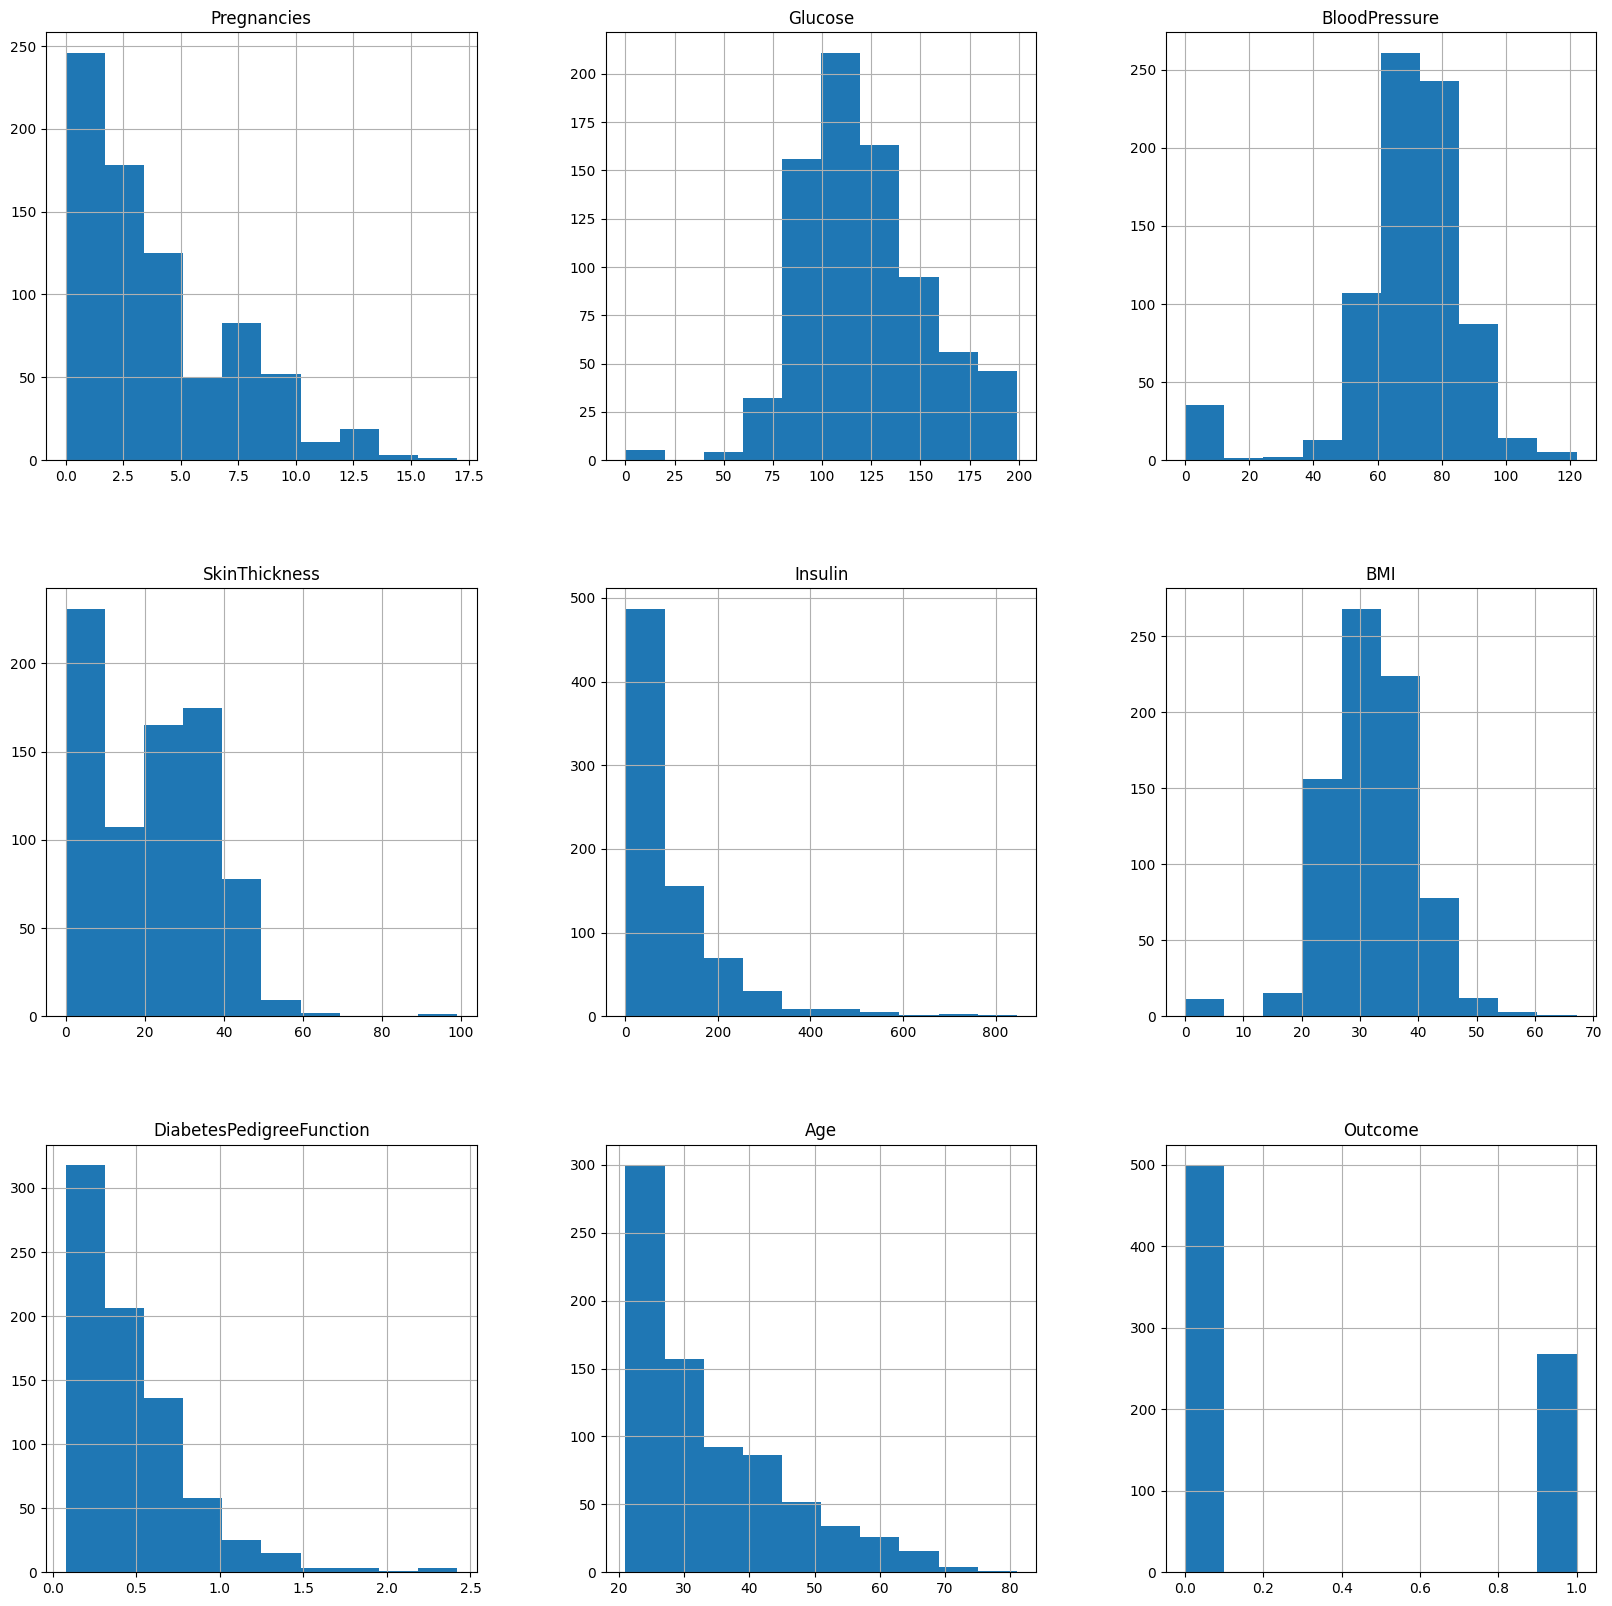

In [31]:
p = diabetes_df.hist(figsize = (20,20))

This code generates histograms for each numerical column in the diabetes_df DataFrame. Histograms are a type of graph that shows the distribution of numerical data. They are useful for understanding the range of values in each column, how frequently different values appear, and if there are any unusual patterns or outliers.

------

Following columns or variables have an invalid zero value:

Glucose
BloodPressure
SkinThickness
Insulin
BMI
It is better to replace zeros with nan since after that counting them would be easier and zeros need to be replaced with suitable value

In [32]:
import numpy as np
diabetes_data_copy = diabetes_df.copy(deep = True)
diabetes_data_copy[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] = diabetes_data_copy[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']].replace(0,np.nan)

## showing the count of Nans
print(diabetes_data_copy.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [33]:
diabetes_data_copy['Glucose'] = diabetes_data_copy['Glucose'].fillna(diabetes_data_copy['Glucose'].mean())
diabetes_data_copy['BloodPressure'] = diabetes_data_copy['BloodPressure'].fillna(diabetes_data_copy['BloodPressure'].mean())
diabetes_data_copy['SkinThickness'] = diabetes_data_copy['SkinThickness'].fillna(diabetes_data_copy['SkinThickness'].median())
diabetes_data_copy['Insulin'] = diabetes_data_copy['Insulin'].fillna(diabetes_data_copy['Insulin'].median())
diabetes_data_copy['BMI'] = diabetes_data_copy['BMI'].fillna(diabetes_data_copy['BMI'].median())

Plotting after replacing null vlues with the mean


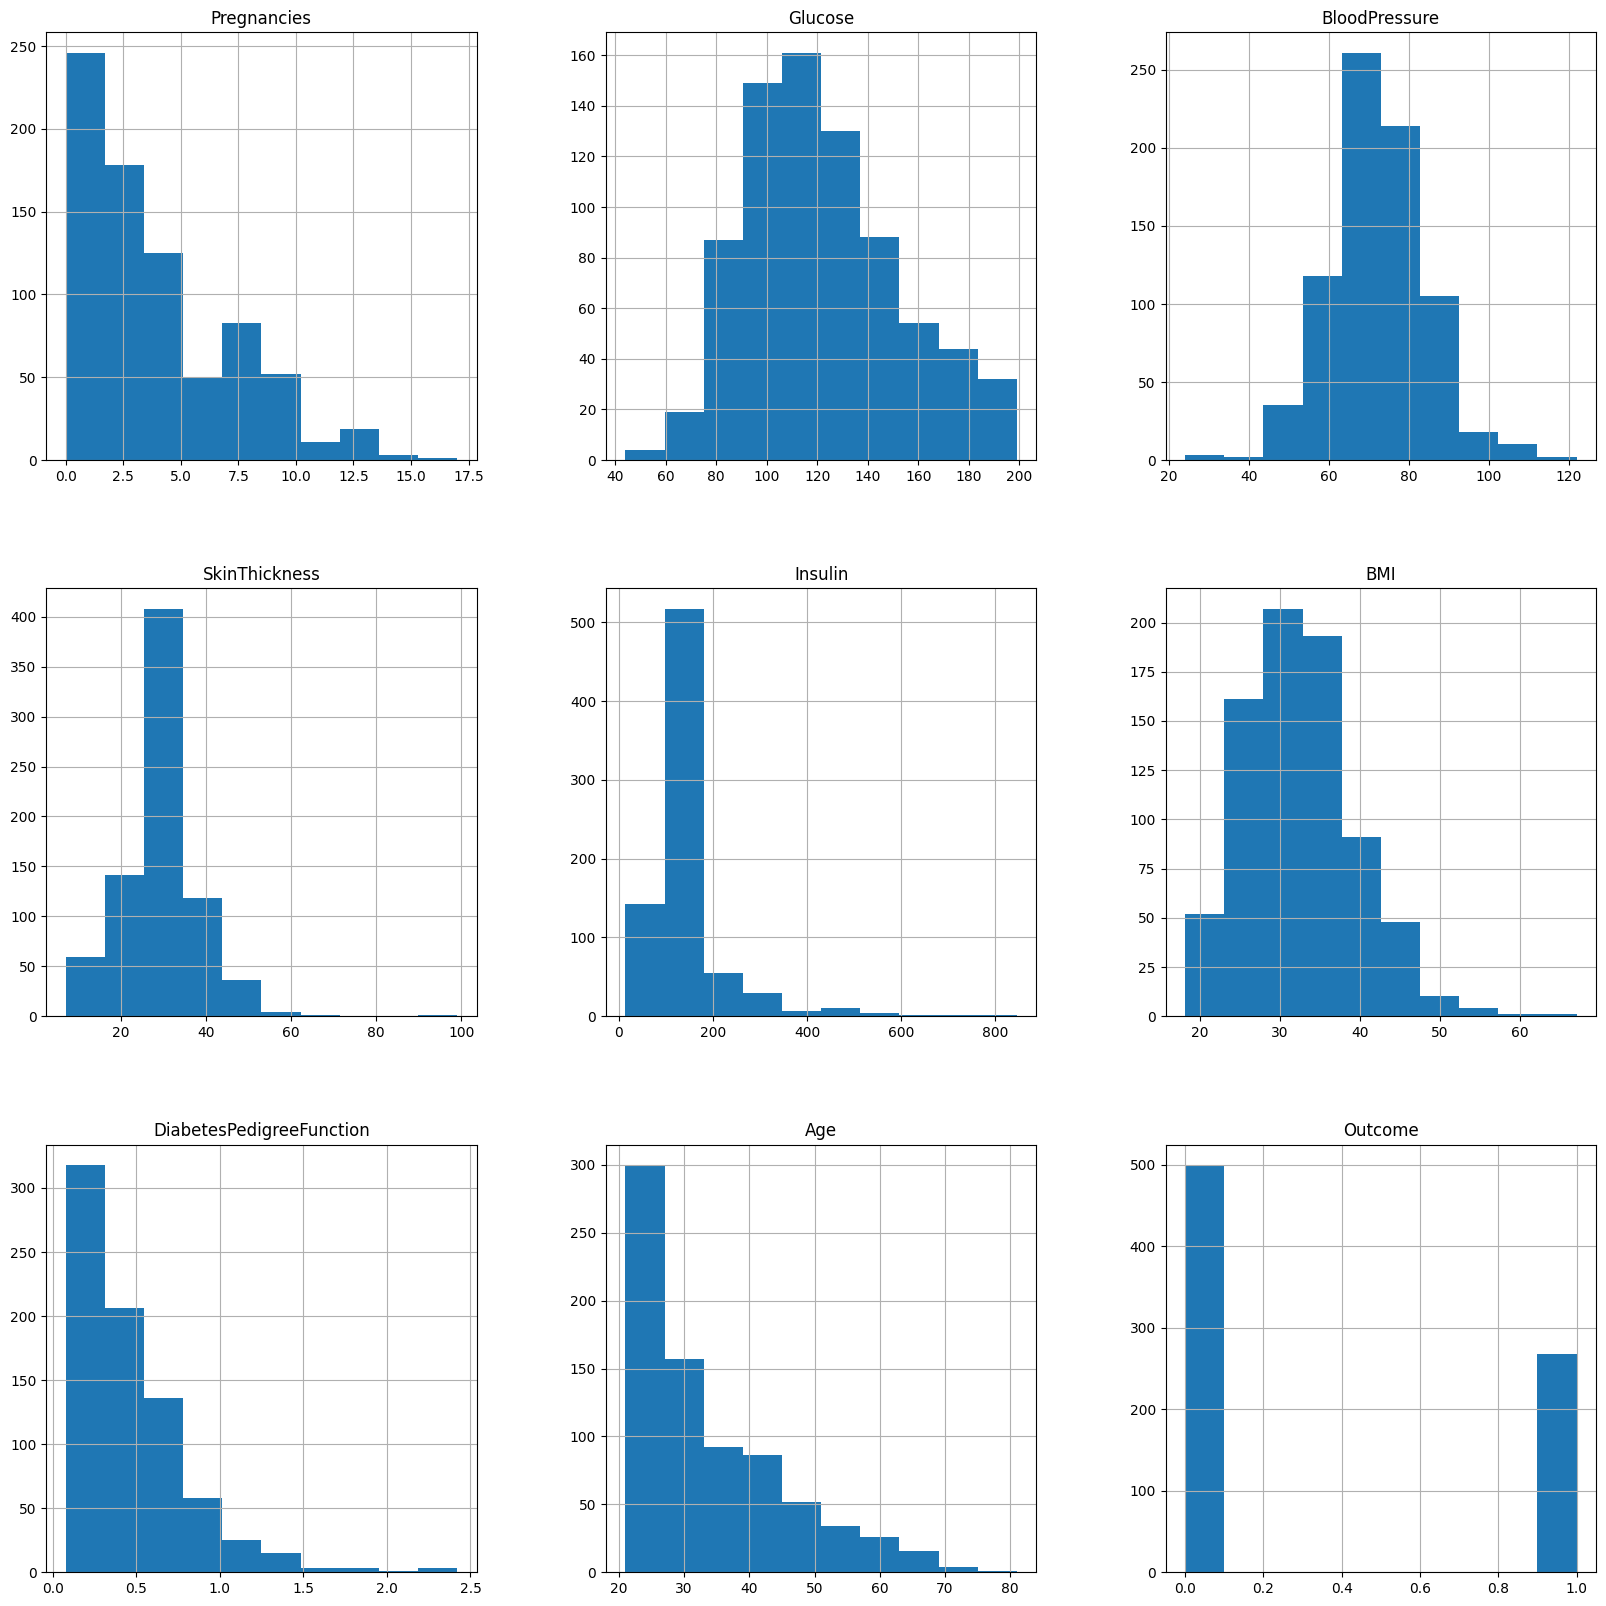

In [34]:
p = diabetes_data_copy.hist(figsize = (20,20))

Diabetes model training

In [35]:
from sklearn.preprocessing import StandardScaler
scaler_diabetes = StandardScaler()
X =  pd.DataFrame(scaler_diabetes.fit_transform(diabetes_data_copy.drop(["Outcome"],axis = 1),),
        columns=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'])

In [36]:
y = diabetes_data_copy.Outcome

In [37]:
#importing train_test_split
from sklearn.model_selection import train_test_split

# Ensure y refers to the diabetes outcome before splitting
y_diabetes_outcome = diabetes_data_copy.Outcome

X_train_diabetes,X_test_diabetes,y_train_diabetes,y_test_diabetes = train_test_split(X,y_diabetes_outcome,test_size=1/3,random_state=42, stratify=y_diabetes_outcome)

# Scale the features using StandardScaler for diabetes data
X_train_diabetes_scaled = scaler_diabetes.transform(X_train_diabetes)
X_test_diabetes_scaled = scaler_diabetes.transform(X_test_diabetes)

In [38]:
# TRAIN MODELS


models_accuracy = {}
models_object = {}

# Logistic Regression
acc_lr, model_lr = fit_ml_models(
    LogisticRegression(max_iter=3000),
    {"C":[0.1,0.5,1]},
    "Logistic Regression",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["Logistic Regression"] = acc_lr
models_object["Logistic Regression"] = model_lr

# KNN
acc_knn, model_knn = fit_ml_models(
    KNeighborsClassifier(),
    {"n_neighbors":[3,5,10]},
    "KNN",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["KNN"] = acc_knn
models_object["KNN"] = model_knn

# SVM
acc_svc, model_svc = fit_ml_models(
    SVC(probability=True),
    {"kernel":["rbf","linear"], "C":[0.5,1]},
    "SVM",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["SVM"] = acc_svc
models_object["SVM"] = model_svc

# Naive Bayes
acc_gnb, model_gnb = fit_ml_models(
    GaussianNB(),
    {},
    "GaussianNB",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["GaussianNB"] = acc_gnb
models_object["GaussianNB"] = model_gnb

# Decision Tree
acc_dt, model_dt = fit_ml_models(
    DecisionTreeClassifier(),
    {"max_depth":[3,6,8]},
    "Decision Tree",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["Decision Tree"] = acc_dt
models_object["Decision Tree"] = model_dt

# Random Forest
acc_rf, model_rf = fit_ml_models(
    RandomForestClassifier(),
    {"max_depth":[3,5,7]},
    "Random Forest",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["Random Forest"] = acc_rf
models_object["Random Forest"] = model_rf

# Extra Trees
acc_et, model_et = fit_ml_models(
    ExtraTreesClassifier(),
    {"max_depth":[3,5,7]},
    "Extra Trees",
    X_train_diabetes_scaled, X_test_diabetes_scaled, y_train_diabetes, y_test_diabetes
)
models_accuracy["Extra Trees"] = acc_et
models_object["Extra Trees"] = model_et


================ Logistic Regression ================
Best Params: {'C': 1}
Train Accuracy: 0.7265625
Test Accuracy: 0.69921875

================ KNN ================
Best Params: {'n_neighbors': 5}
Train Accuracy: 0.77734375
Test Accuracy: 0.6875

================ SVM ================
Best Params: {'C': 1, 'kernel': 'linear'}
Train Accuracy: 0.736328125
Test Accuracy: 0.69140625

================ GaussianNB ================
Best Params: {}
Train Accuracy: 0.763671875
Test Accuracy: 0.72265625

================ Decision Tree ================
Best Params: {'max_depth': 3}
Train Accuracy: 0.79296875
Test Accuracy: 0.7265625

================ Random Forest ================
Best Params: {'max_depth': 5}
Train Accuracy: 0.861328125
Test Accuracy: 0.73828125

================ Extra Trees ================
Best Params: {'max_depth': 5}
Train Accuracy: 0.810546875
Test Accuracy: 0.72265625


In [39]:
# SELECT BEST MODEL
# =============================================================
best_model_name = max(models_accuracy, key=models_accuracy.get)
diabetes_final_model = models_object[best_model_name]

print("\n====================================")
print("BEST MODEL:", best_model_name)
print("Accuracy:", models_accuracy[best_model_name])
print("====================================\n")



BEST MODEL: Random Forest
Accuracy: 0.73828125



In [40]:
# def predict_diabetes(input_data):
#     # Get feature names from the training data (assuming X_train_diabetes was a DataFrame)
#     feature_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
#                    'BMI', 'DiabetesPedigreeFunction', 'Age']

#     # Convert input_data to a DataFrame with feature names
#     input_df = pd.DataFrame([input_data], columns=feature_names)

#     # Scale the input data using scaler_diabetes
#     input_data_scaled = scaler_diabetes.transform(input_df)

#     # Make a prediction
#     prediction = diabetes_final_model.predict(input_data_scaled)[0]

#     # Provide personalized suggestions
#     suggestions = ""

#     if prediction == 1:
#         suggestions += "You may have diabetes. Please consult a healthcare provider for further tests. "
#         # Glucose level advice
#         if input_data[1] > 125:
#             suggestions += "Your glucose level is high. It's essential to monitor your blood sugar regularly."
#         # BMI advice
#         if input_data[5] > 30:
#             suggestions += "You may be at risk due to your BMI. Consider incorporating a healthy diet and regular exercise to manage your weight."
#         # Age advice
#         if input_data[7] > 45:
#             suggestions += "Being older increases the risk of diabetes. Regular health check-ups are recommended."
#     else:
#         suggestions += "You are likely not to have diabetes. However, it is important to maintain a healthy lifestyle. "
#         # Glucose level advice
#         if input_data[1] > 100:
#             suggestions += "Your glucose level is on the higher side. Keep an eye on it and maintain a healthy diet."
#         # BMI advice
#         if input_data[5] > 25:
#             suggestions += "Your BMI suggests you may be at risk. Aim to incorporate more physical activity into your routine."
#         # Age advice
#         if input_data[7] > 40:
#             suggestions += "As you age, the risk for diabetes can increase. Staying active and eating a balanced diet will help."

#     return prediction, suggestions

In [41]:
    # print("Enter the following details for diabetes prediction:")

    # pregnancies = int(input("Number of pregnancies: "))
    # glucose = int(input("Plasma glucose concentration: "))
    # blood_pressure = int(input("Blood pressure: "))
    # skin_thickness = int(input("Skin thickness: "))
    # insulin = int(input("Insulin level: "))
    # bmi = float(input("Body mass index (BMI): "))
    # diabetes_pedigree_function = float(input("Diabetes pedigree function: "))
    # age = int(input("Age: "))

    # # Create input data from user input
    # input_data = [pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, diabetes_pedigree_function, age]

    # # Get the prediction and suggestions
    # prediction, suggestion = predict_diabetes(input_data)

    # # Display the result
    # if prediction == 1:
    #     print("Prediction: You have diabetes.")
    # else:
    #     print("Prediction: You do not have diabetes.")

    # print(suggestion)


Health Diesease Dataset

--------
Import the dataset

In [42]:
heart_df = pd.read_csv('data/heart.csv')
display(heart_df.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Data Cleaning

In [43]:
heart_df.isnull().sum()


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [44]:
heart_df.shape


(303, 14)

In [45]:
print(f"Number of duplicated columns: {heart_df.duplicated().sum()}")

Number of duplicated columns: 1


In [46]:
heart_df.drop_duplicates(inplace = True)

In [47]:
print(f"Number of duplicated columns: {heart_df.duplicated().sum()}")

Number of duplicated columns: 0


Checking the unique values for each column


In [48]:
cols2_to_check = heart_df.columns
for col in cols2_to_check:
    unique_vals = heart_df[col].dropna().unique()
    print(f"\nUnique values in '{col}':")
    for val in unique_vals:
        print(f" - {val}")


Unique values in 'age':
 - 63
 - 37
 - 41
 - 56
 - 57
 - 44
 - 52
 - 54
 - 48
 - 49
 - 64
 - 58
 - 50
 - 66
 - 43
 - 69
 - 59
 - 42
 - 61
 - 40
 - 71
 - 51
 - 65
 - 53
 - 46
 - 45
 - 39
 - 47
 - 62
 - 34
 - 35
 - 29
 - 55
 - 60
 - 67
 - 68
 - 74
 - 76
 - 70
 - 38
 - 77

Unique values in 'sex':
 - 1
 - 0

Unique values in 'cp':
 - 3
 - 2
 - 1
 - 0

Unique values in 'trestbps':
 - 145
 - 130
 - 120
 - 140
 - 172
 - 150
 - 110
 - 135
 - 160
 - 105
 - 125
 - 142
 - 155
 - 104
 - 138
 - 128
 - 108
 - 134
 - 122
 - 115
 - 118
 - 100
 - 124
 - 94
 - 112
 - 102
 - 152
 - 101
 - 132
 - 148
 - 178
 - 129
 - 180
 - 136
 - 126
 - 106
 - 156
 - 170
 - 146
 - 117
 - 200
 - 165
 - 174
 - 192
 - 144
 - 123
 - 154
 - 114
 - 164

Unique values in 'chol':
 - 233
 - 250
 - 204
 - 236
 - 354
 - 192
 - 294
 - 263
 - 199
 - 168
 - 239
 - 275
 - 266
 - 211
 - 283
 - 219
 - 340
 - 226
 - 247
 - 234
 - 243
 - 302
 - 212
 - 175
 - 417
 - 197
 - 198
 - 177
 - 273
 - 213
 - 304
 - 232
 - 269
 - 360
 - 308
 - 245


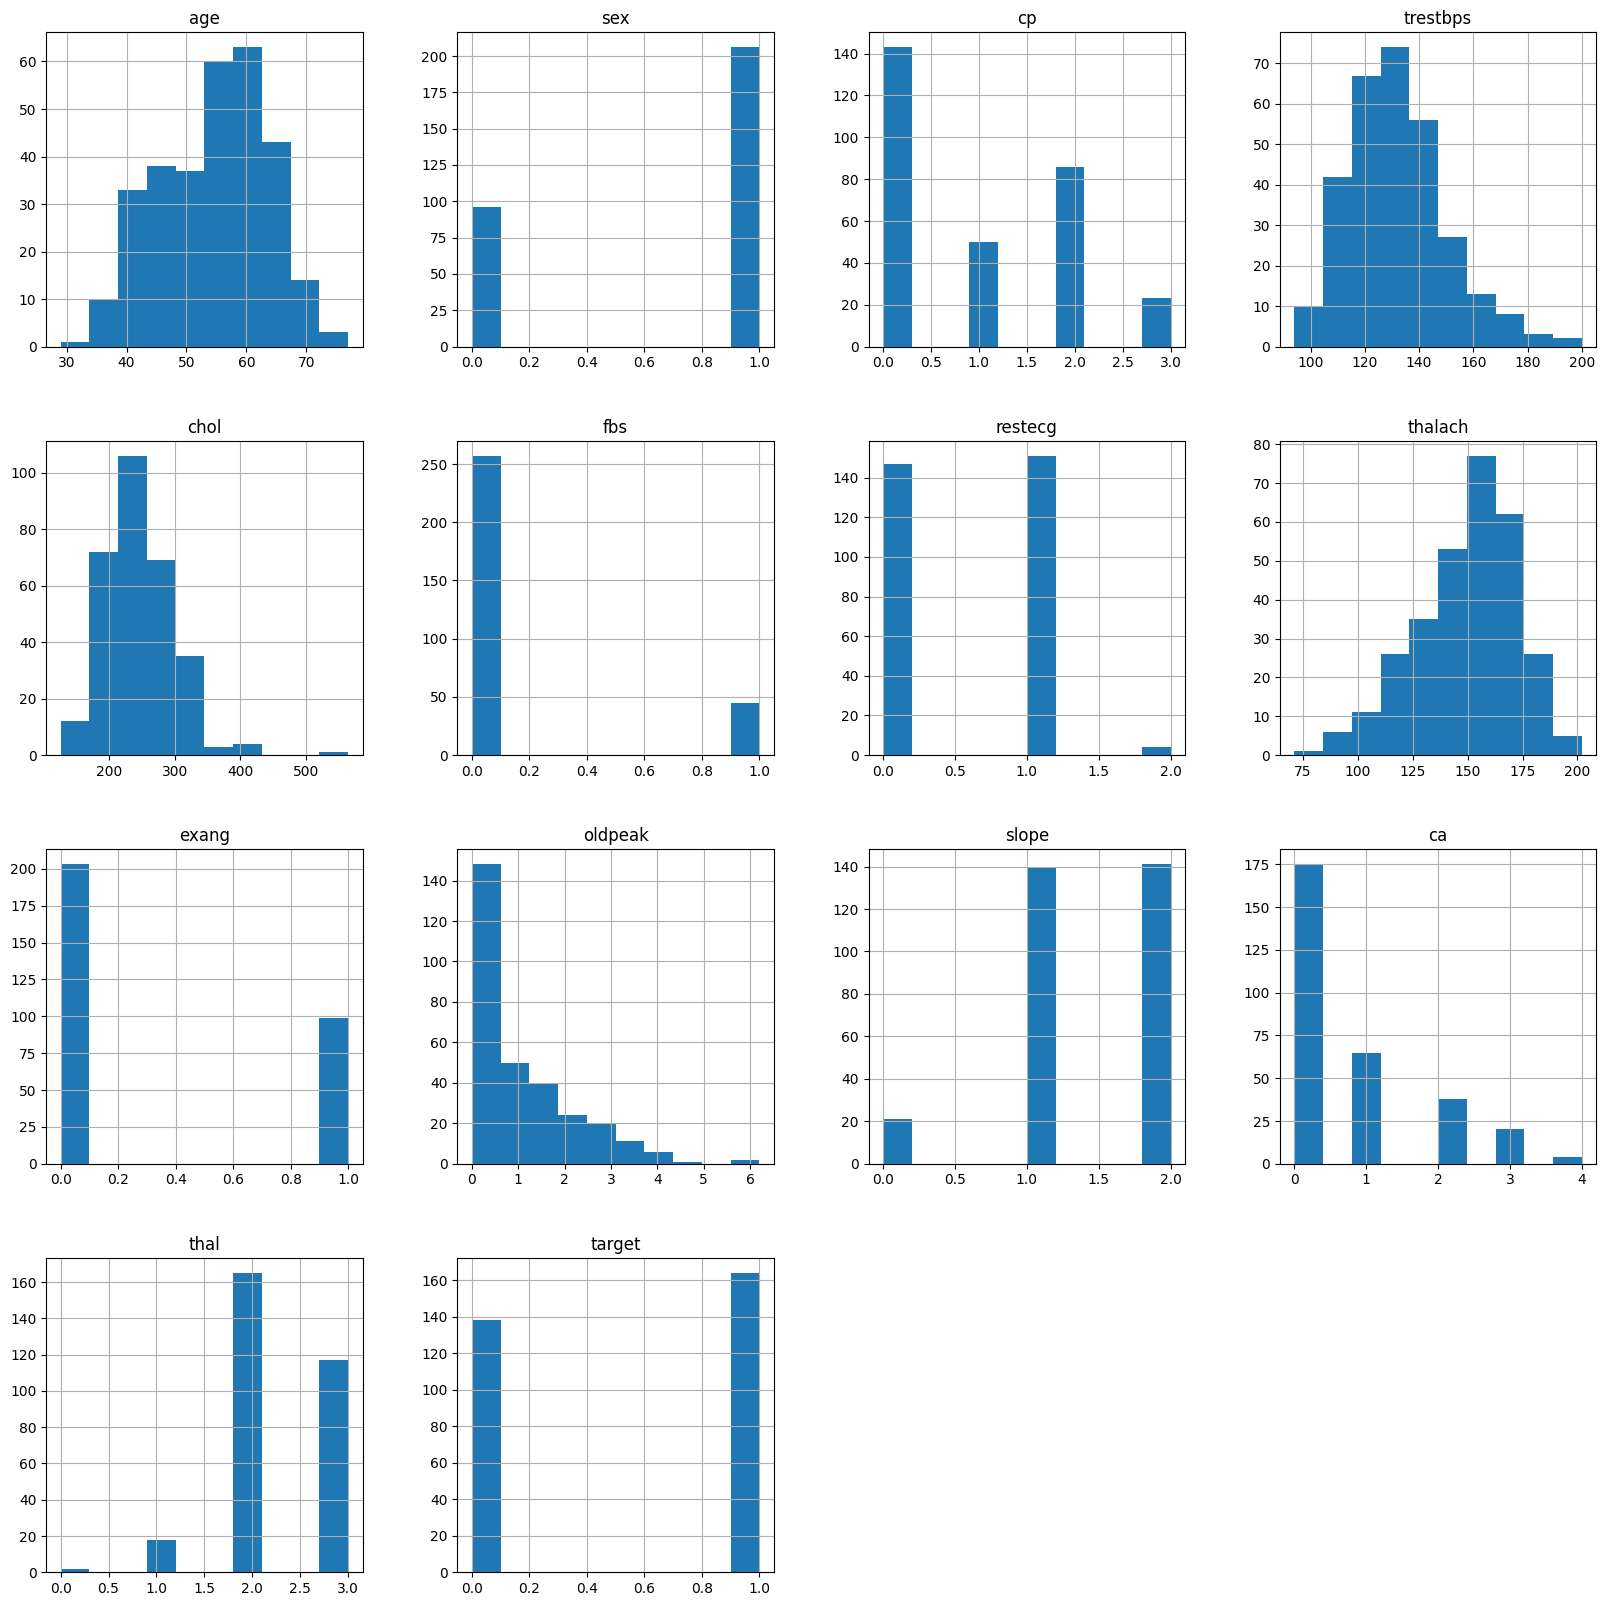

In [49]:
p = heart_df.hist(figsize = (20,20))

target: This is the most crucial variable in our dataset. It indicates the presence of heart disease in the patient.

0: No heart disease (healthy).
1: Presence of heart disease.

-----
chol (Cholesterol): Represents the serum cholesterol level in mg/dl. High cholesterol is a significant risk factor for heart disease.

------

fbs (Fasting Blood Sugar): Indicates whether the patient's fasting blood sugar is greater than 120 mg/dl.

0: Fasting blood sugar <= 120 mg/dl.
1: Fasting blood sugar > 120 mg/dl (an indicator of diabetes, which is a risk factor for heart disease).

-----
slope (The slope of the peak exercise ST segment): This refers to the characteristic of the ST segment during peak exercise on an electrocardiogram (ECG). It's a measure related to how the heart muscle is getting blood flow.

0: Upsloping.
1: Flat.
2: Downsloping.

-----
ca (Number of major vessels colored by fluoroscopy): This refers to the number of major blood vessels (0-3) that are significantly narrowed or blocked, as detected by fluoroscopy (a type of X-ray).

0-3: The number of major vessels (0, 1, 2, or 3).
4: (In some datasets, represents more than 3, or an uninterpretable result).

-----
thal (Thalassemia): This is a blood disorder that affects the production of hemoglobin. In the context of this dataset, it typically refers to a stress thallium scintigraphy result, which evaluates blood flow to the heart muscle. It's often used to diagnose coronary artery disease.

0: (Unknown or missing, sometimes used for normal).
1: Normal blood flow (fixed defect).
2: Reversible defect (blood flow returns to normal after stress).
3: Irreversible defect (constant blood flow problem, often indicating scar tissue from a heart attack)

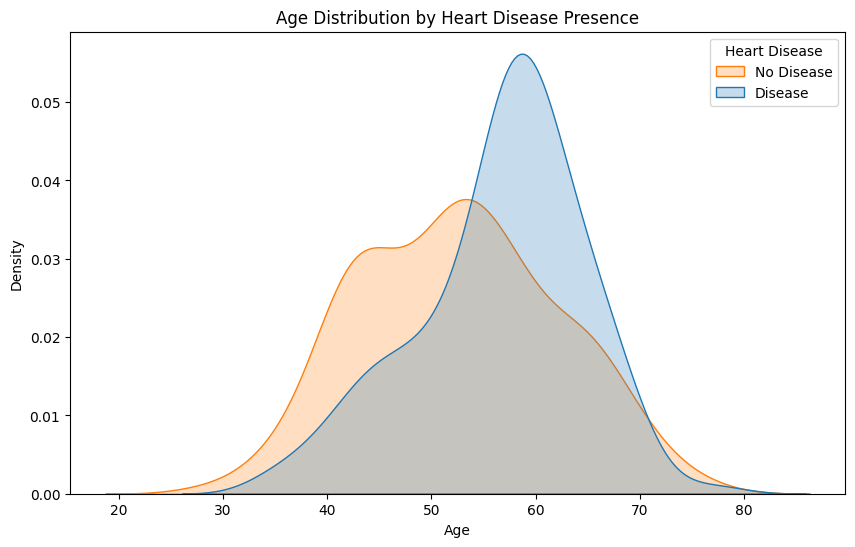

In [50]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=heart_df, x='age', hue='target', fill=True, common_norm=False)
plt.title('Age Distribution by Heart Disease Presence')
plt.xlabel('Age')
plt.ylabel('Density')
plt.legend(title='Heart Disease', labels=['No Disease', 'Disease'])
plt.show()

The plot above shows the distribution of age for individuals with and without heart disease. You can observe the density of each group across different age ranges. This helps in understanding if certain age groups are more prone to heart disease.



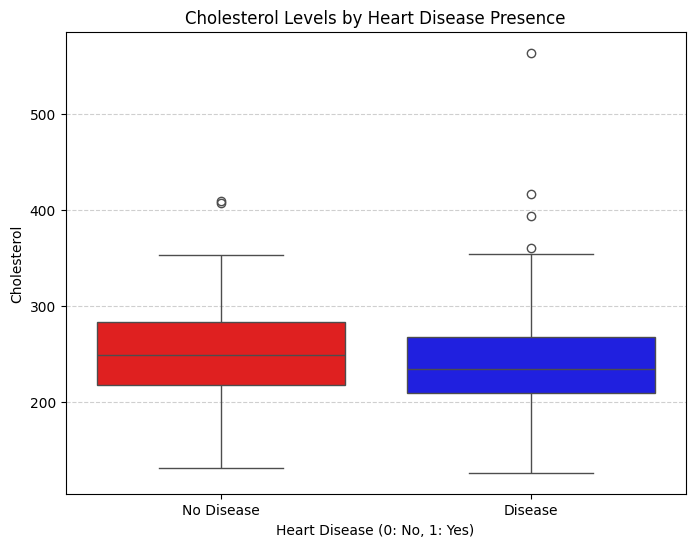

In [70]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=heart_df, x='target', y='chol', hue='target', palette={0: 'red', 1: 'blue'}, legend=False)
plt.title('Cholesterol Levels by Heart Disease Presence')
plt.xlabel('Heart Disease (0: No, 1: Yes)')
plt.ylabel('Cholesterol')
plt.xticks([0, 1], ['No Disease', 'Disease'])
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

This boxplot provides a concise summary of the distribution of cholesterol levels for individuals with and without heart disease. You can see the median, quartiles, and any outliers, helping to identify potential differences between the two groups.

**model_training**

----------
Preparing the Data to train the model

In [52]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [53]:
# SPLIT DATA
X = heart_df.drop("target", axis=1)
y = heart_df["target"]
heart_feature_names = X.columns.tolist()

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42
)

In [54]:
# MODEL TRAINING FUNCTION
def fit_ml_models(algo, params, model_name):
    print(f"\n================ {model_name} ================")
    grid = GridSearchCV(estimator=algo, param_grid=params, cv=5, n_jobs=-1)
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    pred_train = best_model.predict(X_train)
    pred_test = best_model.predict(X_test)

    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)
    best_params = grid.best_params_

    print("Best Params:", best_params)
    print("Train Accuracy:", acc_train)
    print("Test Accuracy:", acc_test)

    return acc_test, best_model


In [55]:
# TRAIN MODELS


models_accuracy = {}
models_object = {}

# Logistic Regression
acc_lr, model_lr = fit_ml_models(
    LogisticRegression(max_iter=3000),
    {"C":[0.1,0.5,1]},
    "Logistic Regression"
)
models_accuracy["Logistic Regression"] = acc_lr
models_object["Logistic Regression"] = model_lr

# KNN
acc_knn, model_knn = fit_ml_models(
    KNeighborsClassifier(),
    {"n_neighbors":[3,5,10]},
    "KNN"
)
models_accuracy["KNN"] = acc_knn
models_object["KNN"] = model_knn

# SVM
acc_svc, model_svc = fit_ml_models(
    SVC(probability=True),
    {"kernel":["rbf","linear"], "C":[0.5,1]},
    "SVM"
)
models_accuracy["SVM"] = acc_svc
models_object["SVM"] = model_svc

# Naive Bayes
acc_gnb, model_gnb = fit_ml_models(
    GaussianNB(),
    {},
    "GaussianNB"
)
models_accuracy["GaussianNB"] = acc_gnb
models_object["GaussianNB"] = model_gnb

# Decision Tree
acc_dt, model_dt = fit_ml_models(
    DecisionTreeClassifier(),
    {"max_depth":[3,6,8]},
    "Decision Tree"
)
models_accuracy["Decision Tree"] = acc_dt
models_object["Decision Tree"] = model_dt

# Random Forest
acc_rf, model_rf = fit_ml_models(
    RandomForestClassifier(),
    {"max_depth":[3,5,7]},
    "Random Forest"
)
models_accuracy["Random Forest"] = acc_rf
models_object["Random Forest"] = model_rf

# Extra Trees
acc_et, model_et = fit_ml_models(
    ExtraTreesClassifier(),
    {"max_depth":[3,5,7]},
    "Extra Trees"
)
models_accuracy["Extra Trees"] = acc_et
models_object["Extra Trees"] = model_et


================ Logistic Regression ================
Best Params: {'C': 1}
Train Accuracy: 0.8584070796460177
Test Accuracy: 0.8421052631578947

================ KNN ================
Best Params: {'n_neighbors': 5}
Train Accuracy: 0.8716814159292036
Test Accuracy: 0.881578947368421

================ SVM ================
Best Params: {'C': 1, 'kernel': 'linear'}
Train Accuracy: 0.8716814159292036
Test Accuracy: 0.8289473684210527

================ GaussianNB ================
Best Params: {}
Train Accuracy: 0.8141592920353983
Test Accuracy: 0.8947368421052632

================ Decision Tree ================
Best Params: {'max_depth': 3}
Train Accuracy: 0.8539823008849557
Test Accuracy: 0.7894736842105263

================ Random Forest ================
Best Params: {'max_depth': 3}
Train Accuracy: 0.8893805309734514
Test Accuracy: 0.881578947368421

================ Extra Trees ================
Best Params: {'max_depth': 5}
Train Accuracy: 0.911504424778761
Test Accuracy: 0.85526315789

In [56]:
# SELECT BEST MODEL
# =============================================================
best_model_name = max(models_accuracy, key=models_accuracy.get)
final_model_heart = models_object[best_model_name]

print("\n====================================")
print("BEST MODEL:", best_model_name)
print("Accuracy:", models_accuracy[best_model_name])
print("====================================\n")



BEST MODEL: GaussianNB
Accuracy: 0.8947368421052632



In [57]:
# #USER INPUT
# print("\n=================================")
# print("    ❤️ HEART DISEASE CHECKUP ")
# print("=================================\n")
# print("Please answer the following questions in a simple way:")

# # Asking simplified questions
# age = int(input("1. How old are you? → "))

# gender = input("2. What is your gender? (male/female) → ").lower()
# sex = 1 if gender == "male" else 0

# chestpain = input("3. Do you sometimes experience chest discomfort or heaviness? (yes/no) → ").lower()
# cp = 2 if chestpain == "yes" else 0

# highbp = input("4. Have you ever been told you have high blood pressure? (yes/no/not sure) → ").lower()
# trestbps = 150 if highbp == "yes" else (heart_df["trestbps"].mean() if highbp == "not sure" else 120)

# cholesterol = input("5. Have you been told you have high cholesterol? (yes/no/not sure) → ").lower()
# chol = 260 if cholesterol == "yes" else (heart_df["chol"].mean() if cholesterol == "not sure" else 200)

# tired = input("6. Do you get tired easily during normal activity? (yes/no) → ").lower()
# thalach = 120 if tired == "yes" else 160

# exang = input("7. Do you feel chest pain during physical activity? (yes/no) → ").lower()
# exang_val = 1 if exang == "yes" else 0

# diabetes = input("8. Do you have diabetes? (yes/no/not sure) → ").lower()
# fbs = 1 if diabetes == "yes" else 0

# abnormal_ecg = input("9. Have doctors ever mentioned an abnormal ECG reading? (yes/no/not sure) → ").lower()
# restecg = 1 if abnormal_ecg == "yes" else 0

# family = input("10. Does anyone in your family have heart disease? (yes/no) → ").lower()
# family_history = 1 if family == "yes" else 0

# # Average placeholder values
# oldpeak = heart_df["oldpeak"].mean()
# slope = 1
# ca = 0
# thal = 2

# # Building final feature set
# user_input_heart = pd.DataFrame([[age, sex, cp, trestbps, chol, fbs, restecg,
#     thalach, exang_val, oldpeak, slope, ca, thal]], columns=X.columns)

# # =============================================================
# # SCALE USER INPUT
# # =============================================================
# user_input_heart_scaled = scaler.transform(user_input_heart)

# # =============================================================
# # USE THE FINAL TRAINED MODEL
# # =============================================================
# prediction = final_model_heart.predict(user_input_heart_scaled)[0]
# probability = final_model_heart.predict_proba(user_input_heart_scaled)[0][1] * 100

# # RESULT
# print("\n=================================")
# print("         RESULT ANALYSIS")
# print("=================================\n")

# if prediction == 1:
#     print("⚠️ POSSIBLE HEART RISK DETECTED ⚠️")
#     print(f"Risk Probability: {probability:.2f}%")
# else:
#     print("✔ LOW RISK — Heart condition seems normal")
#     print(f"Risk Probability: {probability:.2f}%")

# print("\n=================================")
# print("       HEALTH RECOMMENDATIONS")
# print("=================================\n")

# if prediction == 1:
#     print("- Consider consulting a cardiologist")
#     print("- Monitor your blood pressure regularly")
#     print("- Avoid deep-fried or high-fat foods")
#     print("- Manage stress and avoid smoking")
#     print("- Maintain regular physical exercise")
# else:
#     print("- Continue healthy diet & exercise routine")
#     print("- Avoid smoking and stress")
#     print("- Maintain regular checkups")

# print("\n=================================\n")


-----------
-----------

The final I/O for the user

Includes the health summary and the recommentations

----------
----------

In [58]:
def get_unified_user_input():
    print("\n======================================================")
    print("           COMPREHENSIVE HEALTH CHECKUP")
    print("======================================================")
    print("Please provide the following information:")

    # --- General Information ---
    gender = input("1. What is your gender? (Male/Female): ").strip().capitalize()
    age = int(input("2. How old are you? (e.g., 30): "))
    occupation = input("3. What is your occupation? (e.g., Engineer, Teacher, Doctor): ").strip().title()

    # --- Sleep Disorder Specific Information ---
    print("\n--- Sleep Health ---")
    sleep_duration = float(input("4. How many hours do you typically sleep per day? (e.g., 7.5): "))
    quality_of_sleep = int(input("5. On a scale of 1-10, how would you rate your sleep quality? (1=very poor, 10=excellent): "))
    physical_activity = int(input("6. What is your typical physical activity level per day? (minutes, e.g., 60): "))
    stress_level = int(input("7. On a scale of 1-10, what is your typical stress level? (1=very low, 10=very high): "))
    daily_steps = int(input("8. How many steps do you typically take per day? (e.g., 8000): "))
    height  = input("9. What is your Height? (in centimeters): ")
    weight  = input("10. What is your weight? (in kilograms): ")

    # Blood Pressure will be split for sleep and diabetes models
    blood_pressure_str = input("11. What is your Blood Pressure? (Systolic/Diastolic, e.g., 120/80): ").strip()
    systolic_bp, diastolic_bp = map(float, blood_pressure_str.split('/'))
    heart_rate = int(input("12. What is your resting heart rate? (beats per minute, e.g., 70): "))

    # --- Diabetes Specific Information ---
    print("\n--- Diabetes Risk ---")
    pregnancies = int(input("13. How many times have you been pregnant? (0 for males/not applicable, e.g., 1): "))
    glucose = int(input("14. What is your plasma glucose concentration? (mg/dL, e.g., 100): "))
    skin_thickness = int(input("15. What is your triceps skin fold thickness? (mm, e.g., 20): "))
    insulin = int(input("16. What is your 2-hour serum insulin? (mu U/ml, e.g., 80): "))
    diabetes_pedigree_function = float(input("17. What is your diabetes pedigree function value? (e.g., 0.351): "))

    # --- Heart Disease Specific Information ---
    print("\n--- Heart Health ---")
    chestpain = input("18. Do you sometimes experience chest discomfort or heaviness? (yes/no): ").strip().lower()
    trestbps_heart = float(input("19. What is your resting blood pressure? (mm Hg, e.g., 120): ")) # Separate input for heart model if needed, or use systolic_bp
    cholesterol_heart = float(input("20. What is your serum cholesterol level? (mg/dL, e.g., 200): "))
    fbs = input("21. Is your fasting blood sugar > 120 mg/dL? (yes/no): ").strip().lower()
    restecg = int(input("22. What is your resting electrocardiographic results? (0=normal, 1=ST-T wave abnormality, 2=left ventricular hypertrophy): "))
    thalach = int(input("23. What is your maximum heart rate achieved? (bpm, e.g., 150): "))
    exang = input("24. Do you experience exercise-induced angina? (yes/no): ").strip().lower()
    oldpeak = float(input("25. What is your ST depression induced by exercise relative to rest? (e.g., 2.3): "))
    slope = int(input("26. What is the slope of the peak exercise ST segment? (0=upsloping, 1=flat, 2=downsloping): "))
    ca = int(input("27. Number of major vessels (0-3) colored by fluoroscopy? (e.g., 0): "))
    thal = int(input("28. What is your Thalassemia type? (1=normal, 2=fixed defect, 3=reversible defect): "))

    return {
        'gender': gender, 'age': age, 'occupation': occupation,
        'sleep_duration': sleep_duration, 'quality_of_sleep': quality_of_sleep,
        'physical_activity': physical_activity, 'stress_level': stress_level,
        'daily_steps': daily_steps, 'height': height, 'weight': weight,
        'systolic_bp': systolic_bp, 'diastolic_bp': diastolic_bp, 'heart_rate': heart_rate,
        'pregnancies': pregnancies, 'glucose': glucose, 'skin_thickness': skin_thickness,
        'insulin': insulin, 'diabetes_pedigree_function': diabetes_pedigree_function,
        'chestpain': chestpain, 'trestbps_heart': trestbps_heart, 'cholesterol_heart': cholesterol_heart,
        'fbs': fbs, 'restecg': restecg, 'thalach': thalach, 'exang': exang,
        'oldpeak': oldpeak, 'slope': slope, 'ca': ca, 'thal': thal
    }

In [71]:
user_health_data = get_unified_user_input()


           COMPREHENSIVE HEALTH CHECKUP
Please provide the following information:


KeyboardInterrupt: Interrupted by user

In [ ]:
# @title
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# --- Process for Sleep Disorder Model ---

# Explicitly re-fit LabelEncoders for all categorical columns used by the sleep model
# This ensures their .classes_ attribute is a proper numpy array and ready for string input.
bmi = float(user_health_data['weight']) / (float(user_health_data['height']) ** 2)
def get_bmi_category(bmi):
    """
    This function maps the BMI value to a category:
    - 'Normal' for BMI between 18.5 and 24.9
    - 'Overweight' for BMI between 25 and 29.9
    - 'Obese' for BMI 30 and above
    """
    if 18.5 <= bmi < 25:
        return "Normal"
    elif 25 <= bmi < 30:
        return "Overweight"
    else:
        return "Obese"

bmi_category = get_bmi_category(bmi)


# Transform the input using the LabelEncoders
gender_encoded = sleep_label_encoders['Gender'].transform([user_health_data['gender']])[0]
bmi_encoded = sleep_label_encoders['BMI Category'].transform([bmi_category])[0]
occupation = user_health_data['occupation']
# Handle unseen occupation by adding it to the encoder if it's not already there
if occupation not in sleep_label_encoders['Occupation'].classes_:
  # Dynamically add the new occupation
  sleep_label_encoders['Occupation'].classes_ = list(sleep_label_encoders['Occupation'].classes_) + [occupation]
  occupation_encoded = sleep_label_encoders['Occupation'].transform([occupation])[0]
else:
  occupation_encoded = sleep_label_encoders['Occupation'].transform([occupation])[0]

sleep_feature_names = ['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep',
                     'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate',
                     'Daily Steps', 'Systolic_BP', 'Diastolic_BP']

sleep_input_data = [
    gender_encoded,
    user_health_data['age'],
    occupation_encoded,
    user_health_data['sleep_duration'],
    user_health_data['quality_of_sleep'],
    user_health_data['physical_activity'],
    user_health_data['stress_level'],
    bmi_encoded,
    user_health_data['heart_rate'],
    user_health_data['daily_steps'],
    user_health_data['systolic_bp'],
    user_health_data['diastolic_bp']
]

sleep_input_df = pd.DataFrame([sleep_input_data], columns=sleep_feature_names)
sleep_input_scaled = scaler_sleep.transform(sleep_input_df)
sleep_prediction_encoded = sleep_model.predict(sleep_input_scaled)[0]
sleep_probability = sleep_model.predict_proba(sleep_input_scaled)[0][sleep_prediction_encoded] * 100
sleep_decoded_prediction = sleep_label_encoders['Sleep Disorder'].inverse_transform([sleep_prediction_encoded])[0]

# --- Process for Diabetes Model ---
# Ensure diabetes input features are in the correct order as per X_train_diabetes
diabetes_feature_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
                           'BMI', 'DiabetesPedigreeFunction', 'Age']


diabetes_input_data = [
    user_health_data['pregnancies'],
    user_health_data['glucose'],
    user_health_data['systolic_bp'], # Using systolic BP as general blood pressure
    user_health_data['skin_thickness'],
    user_health_data['insulin'],
    bmi,
    user_health_data['diabetes_pedigree_function'],
    user_health_data['age']
]

diabetes_input_df = pd.DataFrame([diabetes_input_data], columns=diabetes_feature_names)
diabetes_input_scaled = scaler_diabetes.transform(diabetes_input_df)
diabetes_prediction = diabetes_final_model.predict(diabetes_input_scaled)[0]

# --- Process for Heart Disease Model ---
# Map user input to encoded values for heart model
heart_sex_encoded = 1 if user_health_data['gender'].lower() == 'male' else 0
heart_cp_encoded = 2 if user_health_data['chestpain'].lower() == 'yes' else 0 # Simplified mapping
heart_fbs_encoded = 1 if user_health_data['fbs'].lower() == 'yes' else 0
heart_exang_encoded = 1 if user_health_data['exang'].lower() == 'yes' else 0

# heart_feature_names = X.columns.tolist() # Get feature names from the original X_heart DataFrame
heart_input_data = [
    user_health_data['age'],
    heart_sex_encoded,
    heart_cp_encoded,
    user_health_data['trestbps_heart'],
    user_health_data['cholesterol_heart'],
    heart_fbs_encoded,
    user_health_data['restecg'],
    user_health_data['thalach'],
    heart_exang_encoded,
    user_health_data['oldpeak'],
    user_health_data['slope'],
    user_health_data['ca'],
    user_health_data['thal']
]
heart_input_df = pd.DataFrame([heart_input_data], columns=heart_feature_names)
heart_input_scaled = scaler.transform(heart_input_df)
heart_prediction = final_model_heart.predict(heart_input_scaled)[0]
heart_probability = final_model_heart.predict_proba(heart_input_scaled)[0][1] * 100

# --- Display Results and Recommendations ---
print("\n======================================================")
print("                COMPREHENSIVE HEALTH REPORT")
print("======================================================")

print("\n--- Sleep Disorder Prediction ---")
print(f"Predicted Sleep Disorder: {sleep_decoded_prediction}")
print(f"Probability: {sleep_probability:.2f}%")

print("\n--- Diabetes Prediction ---")
if diabetes_prediction == 1:
    print("Predicted Diabetes Risk: High (Positive)")
else:
    print("Predicted Diabetes Risk: Low (Negative)")

print("\n--- Heart Disease Prediction ---")
if heart_prediction == 1:
    print(f"Predicted Heart Disease Risk: High (Probability: {heart_probability:.2f}%)")
else:
    print(f"Predicted Heart Disease Risk: Low (Probability: {heart_probability:.2f}%)")

print("\n======================================================")
print("                 PERSONALIZED RECOMMENDATIONS")
print("======================================================")

# Sleep Recommendations
print("\n--- Sleep Health Recommendations ---")
if sleep_decoded_prediction == 'None':
    if user_health_data['sleep_duration'] < 7.0:
        print(f"- Your reported sleep duration of {user_health_data['sleep_duration']} hours is on the lower side. Aim for 7-9 hours of sleep for optimal health.")
    if user_health_data['quality_of_sleep'] < 7:
        print(f"- Your reported quality of sleep is {user_health_data['quality_of_sleep']}. Consider improving your sleep environment for better rest.")
    if user_health_data['physical_activity'] < 40:
        print(f"- Your physical activity level of {user_health_data['physical_activity']} is a bit low. Regular moderate exercise can further enhance sleep.")
    if user_health_data['stress_level'] > 5:
        print(f"- Even without a diagnosed disorder, your stress level of {user_health_data['stress_level']} is elevated. Practicing relaxation techniques can improve overall well-being.")
    if bmi_category in ['Overweight', 'Obese']:
        print(f"- Although no disorder was predicted, your BMI category is {bmi_category}. Maintaining a healthy weight is beneficial for long-term sleep health.")
    if user_health_data['daily_steps'] < 6000:
        print(f"- Your daily steps of {user_health_data['daily_steps']} are below average. Increasing your daily activity can contribute to better sleep.")
elif sleep_decoded_prediction == 'Insomnia':
    if user_health_data['sleep_duration'] < 6.0:
        print(f"- Your very low sleep duration ({user_health_data['sleep_duration']} hours) is a key factor in insomnia. Focus on consistent bedtime and wake-up times.")
    if user_health_data['quality_of_sleep'] < 5:
        print(f"- Improving your sleep quality ({user_health_data['quality_of_sleep']}) is crucial. Ensure your bedroom is dark, quiet, and cool.")
    if user_health_data['stress_level'] > 6:
        print(f"- Your high stress level ({user_health_data['stress_level']}) is likely contributing to insomnia. Explore stress-reduction methods like meditation or yoga.")
elif sleep_decoded_prediction == 'Sleep Apnea':
    if bmi_category == 'Obese':
        print(f"- Your BMI category is {bmi_category}, which is a significant risk factor for sleep apnea. Weight management is highly recommended.")
    if user_health_data['age'] > 50:
        print(f"- Your age ({user_health_data['age']}) increases the likelihood of sleep apnea. Regular check-ups with a doctor are important.")
    if user_health_data['gender'] == 'Male':
        print("- As a male, you have a higher predisposition to sleep apnea. Be vigilant about symptoms.")

# Diabetes Recommendations
print("\n--- Diabetes Recommendations ---")
diabetes_suggestions = ""
if diabetes_prediction == 1:
    diabetes_suggestions += "- You may have diabetes. Please consult a healthcare provider for further tests.\n"
    if user_health_data['glucose'] > 125:
        diabetes_suggestions += "- Your glucose level is high. It's essential to monitor your blood sugar regularly.\n"
    if bmi_category == 'Obese': # Use BMI category for simplified check
        diabetes_suggestions += "- You may be at risk due to your BMI. Consider incorporating a healthy diet and regular exercise to manage your weight.\n"
    if user_health_data['age'] > 45:
        diabetes_suggestions += "- Being older increases the risk of diabetes. Regular health check-ups are recommended.\n"
else:
    diabetes_suggestions += "- You are likely not to have diabetes. However, it is important to maintain a healthy lifestyle.\n"
    if user_health_data['glucose'] > 100:
        diabetes_suggestions += "- Your glucose level is on the higher side. Keep an eye on it and maintain a healthy diet.\n"
    if bmi_category in ['Overweight', 'Obese']:
        diabetes_suggestions += "- Your BMI suggests you may be at risk. Aim to incorporate more physical activity into your routine.\n"
    if user_health_data['age'] > 40:
        diabetes_suggestions += "- As you age, the risk for diabetes can increase. Staying active and eating a balanced diet will help.\n"
print(diabetes_suggestions)

# Heart Disease Recommendations
print("\n--- Heart Disease Recommendations ---")
if heart_prediction == 1:
    print("- Consider consulting a cardiologist")
    print("- Monitor your blood pressure regularly")
    print("- Avoid deep-fried or high-fat foods")
    print("- Manage stress and avoid smoking")
else:
    print("- Continue healthy diet & exercise routine")
    print("- Avoid smoking and stress")
    print("- Maintain regular checkups")

print("\n======================================================")